# Análisis de bajas de socios: ¿por qué se van y cuándo?

**Alumna:** Sofia Salto

## Objetivo del análisis

Analizar las bajas de socios registradas entre junio de 2025 y julio de 2026, con el propósito de identificar los principales motivos de desvinculación y observar cómo evolucionaron las bajas a lo largo del período.

## Pregunta principal

¿Por qué se dan de baja los socios y cómo evolucionaron las bajas mes a mes entre junio de 2025 y julio de 2026?

## Preguntas específicas

1. ¿Cuáles son los principales motivos de baja?

2. ¿En qué meses se concentra la mayor cantidad de bajas?

3. ¿Cómo varían las bajas según la edad de los socios?

4. ¿Cómo varían las bajas según la antigüedad de los socios?

## Fuente de datos

Se utiliza un registro interno de bajas de socios, compuesto por **951 filas y 13 columnas**. La información fue anonimizada para preservar la identidad de las personas.

## Importación de librerías

Para realizar el análisis se utilizan las librerías Pandas, Matplotlib y Seaborn.

- **Pandas:** permite cargar, organizar y analizar los datos.
- **Matplotlib:** permite crear gráficos para visualizar los resultados.
- **Seaborn:** facilita la creación de gráficos estadísticos.

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Carga de la base de datos

Se importa el archivo Excel anonimizado utilizando Pandas para trabajar con la información desde Google Colab. Los datos se almacenan en un DataFrame llamado `df`, que será nuestra base de trabajo para realizar los análisis.

In [37]:
df = pd.read_excel('/content/BAJAS DESDE JUNIO 2025 HASTA AGOSTO 2026 ANONIMIZADO.xlsx')

In [38]:
df.head()

,N° SOCIO,APELLIDO Y NOMBRE,F. BAJA,MOTIVO. AF,F. INGRESO,ANTIGÜEDAD COMO SOCIO,F. NACIMIENTO,EDAD,MOTIVO (desplegable),DESCUENTO,DEPORTE,PAIS y/o PROVINCIA,COUNTRY/ CLUB
0,900009,SOCIO 0439,2025-06-02,RENUNCIA,2011-04-11,14 años,1973-12-05,51 años,MOTIVOS PERSONALES,NO,NaN,NaN,NaN
1,900895,SOCIO 0255,2025-06-02,RENUNCIA,2024-07-30,0 años,2012-10-15,12 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
2,900287,SOCIO 0335,2025-06-11,RENUNCIA,2005-02-02,20 años,2002-02-26,23 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
3,900037,SOCIO 0583,2025-06-11,RENUNCIA,2009-12-09,15 años,1972-12-28,52 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
4,900883,SOCIO 0516,2025-06-11,RENUNCIA,2009-12-09,15 años,2005-05-11,20 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN


## Exploración inicial de los datos

En esta etapa se realiza una primera revisión de la base para conocer su estructura, la cantidad de registros, las columnas disponibles y los tipos de datos. Esto permite verificar que la información se haya importado correctamente y entender con qué datos contamos para el análisis.

In [39]:
df.shape

(951, 13)

In [40]:
df.columns

Index(['N° SOCIO', 'APELLIDO Y NOMBRE', 'F. BAJA', 'MOTIVO. AF', 'F. INGRESO',
       'ANTIGÜEDAD COMO SOCIO', 'F. NACIMIENTO', 'EDAD',
       'MOTIVO (desplegable)', 'DESCUENTO', 'DEPORTE', 'PAIS y/o PROVINCIA',
       'COUNTRY/ CLUB '],
      dtype='object')

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 951 entries, 0 to 950
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   N° SOCIO               951 non-null    int64         
 1   APELLIDO Y NOMBRE      951 non-null    object        
 2   F. BAJA                951 non-null    datetime64[ns]
 3   MOTIVO. AF             951 non-null    object        
 4   F. INGRESO             951 non-null    datetime64[ns]
 5   ANTIGÜEDAD COMO SOCIO  951 non-null    object        
 6   F. NACIMIENTO          951 non-null    datetime64[ns]
 7   EDAD                   951 non-null    object        
 8   MOTIVO (desplegable)   951 non-null    object        
 9   DESCUENTO              951 non-null    object        
 10  DEPORTE                123 non-null    object        
 11  PAIS y/o PROVINCIA     51 non-null     object        
 12  COUNTRY/ CLUB          104 non-null    object        
dtypes: da

In [42]:
df.columns.tolist()

['N° SOCIO',
 'APELLIDO Y NOMBRE',
 'F. BAJA',
 'MOTIVO. AF',
 'F. INGRESO',
 'ANTIGÜEDAD COMO SOCIO',
 'F. NACIMIENTO',
 'EDAD',
 'MOTIVO (desplegable)',
 'DESCUENTO',
 'DEPORTE',
 'PAIS y/o PROVINCIA',
 'COUNTRY/ CLUB ']

## Revisión de datos vacíos y duplicados

Se revisa la existencia de valores vacíos y registros duplicados en la base de datos. Esta comprobación permite identificar posibles inconsistencias y distinguir los campos que no fueron completados de aquellos que no corresponden según el motivo de la baja.

In [43]:
df.isnull().sum()

,0
N° SOCIO,0
APELLIDO Y NOMBRE,0
F. BAJA,0
MOTIVO. AF,0
F. INGRESO,0
ANTIGÜEDAD COMO SOCIO,0
F. NACIMIENTO,0
EDAD,0
MOTIVO (desplegable),0
DESCUENTO,0


**Aclaración sobre los campos vacíos:** Las columnas DEPORTE, PAIS y/o PROVINCIA y COUNTRY/ CLUB contienen valores vacíos porque son campos que se completan únicamente cuando la baja está relacionada con alguna de esas situaciones específicas. Por ejemplo, cuando un socio deja de practicar un deporte, se muda a otra provincia o país, o se traslada a otro country o club. Por este motivo, los espacios en blanco no representan necesariamente datos faltantes o errores de carga, sino información que no corresponde completar en todos los casos. Se decidió conservar estos valores sin reemplazarlos ni eliminarlos.

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.head()

,N° SOCIO,APELLIDO Y NOMBRE,F. BAJA,MOTIVO. AF,F. INGRESO,ANTIGÜEDAD COMO SOCIO,F. NACIMIENTO,EDAD,MOTIVO (desplegable),DESCUENTO,DEPORTE,PAIS y/o PROVINCIA,COUNTRY/ CLUB
0,900009,SOCIO 0439,2025-06-02,RENUNCIA,2011-04-11,14 años,1973-12-05,51 años,MOTIVOS PERSONALES,NO,NaN,NaN,NaN
1,900895,SOCIO 0255,2025-06-02,RENUNCIA,2024-07-30,0 años,2012-10-15,12 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
2,900287,SOCIO 0335,2025-06-11,RENUNCIA,2005-02-02,20 años,2002-02-26,23 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
3,900037,SOCIO 0583,2025-06-11,RENUNCIA,2009-12-09,15 años,1972-12-28,52 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN
4,900883,SOCIO 0516,2025-06-11,RENUNCIA,2009-12-09,15 años,2005-05-11,20 años,NO UTILIZA EL CLUB CON FRECUENCIA,NO,NaN,NaN,NaN


##Análisis de los motivos de baja

En esta etapa se analizarán los motivos por los cuales los socios solicitan la baja. Para ello, se revisarán tanto los motivos registrados originalmente como los motivos seleccionados en el campo desplegable. Esto permitirá identificar cuáles son las principales causas de baja y conocer cómo se distribuyen.

In [46]:
df['MOTIVO (desplegable)'].value_counts()

,count
MOTIVO (desplegable),
NO HACE NADA EN EL CLUB,144
NO UTILIZA EL CLUB CON FRECUENCIA,126
MOTIVOS PERSONALES,102
PROBLEMAS ECONOMICOS,90
SE VA A OTRO CLUB,72
SE VA A VIVIR A OTRO PAIS/PROVINCIA,50
NO SE ADAPTO A LAS ACTIVIDADES,50
SALUD,43
FIN ALQUILER TEMPORARIO CCHT,38


### Revisión de diferencias en los motivos registrados

Durante la exploración inicial se detectaron motivos que aparecen separados en el conteo, aunque podrían representar la misma categoría. Por ejemplo, se identificaron registros de «SALUD» y «salud», así como una posible repetición de «VENDIO SU PROPIEDAD».

Para determinar si estas diferencias se deben a cuestiones de escritura, se realiza una revisión de los valores originales, teniendo en cuenta el uso de mayúsculas, minúsculas y posibles espacios adicionales. Esta comprobación permitirá unificar las categorías que correspondan antes de continuar con el análisis.

In [47]:
for motivo in df['MOTIVO (desplegable)'].dropna().unique():
    if 'SALUD' in motivo.upper() or 'VENDIO SU PROPIEDAD' in motivo.upper():
        print(repr(motivo))

'SALUD'
'VENDIO SU PROPIEDAD'
'VENDIO SU PROPIEDAD '
'salud'


### Limpieza y normalización de los motivos

Se corrigen las diferencias de escritura detectadas en los motivos de baja. Para ello, se eliminan los espacios adicionales al inicio y al final de los textos y se unifican los registros utilizando mayúsculas.

Esta corrección permite que los motivos iguales sean contabilizados dentro de una misma categoría, evitando que las diferencias de escritura afecten los resultados del análisis.

In [49]:
df['MOTIVO (desplegable)'] = (
    df['MOTIVO (desplegable)']
    .str.strip()
    .str.upper()
)

In [50]:
df['MOTIVO (desplegable)'].value_counts()

,count
MOTIVO (desplegable),
NO HACE NADA EN EL CLUB,144
NO UTILIZA EL CLUB CON FRECUENCIA,126
MOTIVOS PERSONALES,102
PROBLEMAS ECONOMICOS,90
SE VA A OTRO CLUB,72
SE VA A VIVIR A OTRO PAIS/PROVINCIA,50
NO SE ADAPTO A LAS ACTIVIDADES,50
SALUD,44
FIN ALQUILER TEMPORARIO CCHT,38


### Verificación de registros sin motivo

Luego de normalizar los motivos, se verifica que la suma de las categorías coincida con la cantidad total de registros. Esta comprobación permite detectar posibles valores vacíos que podrían quedar excluidos del conteo.

**1. ¿Cuáles son los principales motivos de baja?**

Vamos a incorporar debajo de la tabla de frecuencias una interpretación de los resultados.

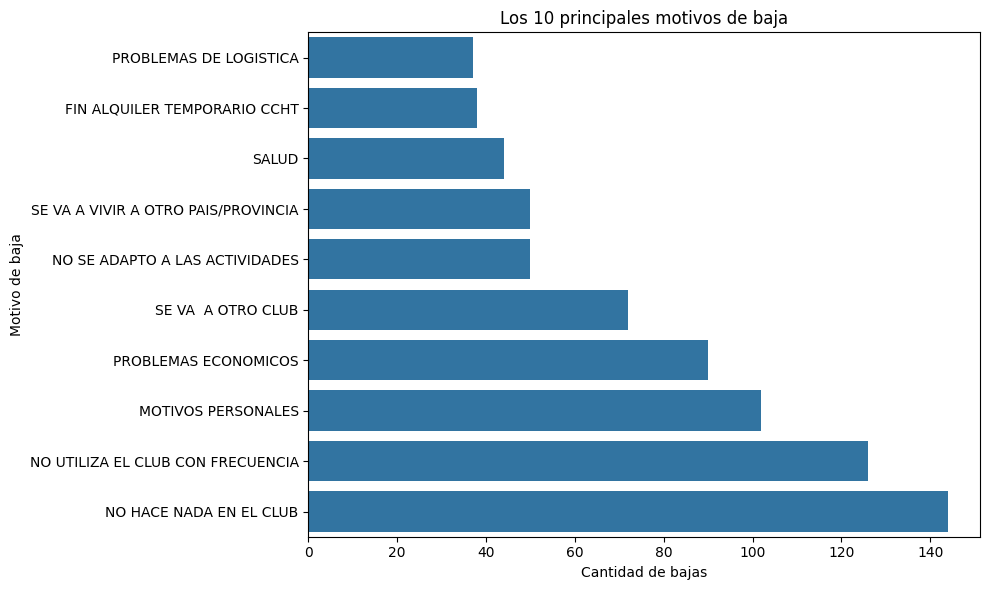

In [53]:
motivos_top10 = df["MOTIVO (desplegable)"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
sns.barplot(x=motivos_top10.values, y=motivos_top10.index)

plt.title("Los 10 principales motivos de baja")
plt.xlabel("Cantidad de bajas")
plt.ylabel("Motivo de baja")

plt.tight_layout()
plt.show()

### Interpretación del gráfico

El gráfico permite observar que los motivos más frecuentes de baja están relacionados principalmente con la falta de participación y utilización del club.

Se destaca que los dos primeros motivos, "NO HACE NADA EN EL CLUB" y "NO UTILIZA EL CLUB CON FRECUENCIA", reúnen la mayor cantidad de registros.

También se observa la presencia de motivos personales y económicos entre las principales causas de baja.

Estos resultados permiten identificar que la falta de actividad y utilización de las instalaciones constituye un aspecto relevante para comprender las bajas de socios.

**2. ¿En qué meses se concentra la mayor cantidad de bajas?**

En esta etapa se analiza la cantidad de bajas registradas en cada mes, considerando el período comprendido entre junio de 2025 y julio de 2026.

El objetivo es identificar los meses en los que se concentra la mayor cantidad de bajas y observar cómo evoluciona esta cantidad a lo largo del período analizado.

In [54]:
# Filtrar las bajas correspondientes al período de análisis
df_periodo = df[
    df["F. BAJA"].between("2025-06-01", "2026-07-31")
].copy()

# Calcular la cantidad de bajas por mes
bajas_por_mes = (
    df_periodo.groupby(df_periodo["F. BAJA"].dt.to_period("M"))
    .size()
    .reindex(
        pd.period_range("2025-06", "2026-07", freq="M"),
        fill_value=0
    )
)

# Mostrar la cantidad de bajas mensuales
tabla_mensual = bajas_por_mes.rename_axis("MES").reset_index(name="CANTIDAD DE BAJAS")

tabla_mensual["MES"] = tabla_mensual["MES"].astype(str)

display(tabla_mensual)

,MES,CANTIDAD DE BAJAS
0,2025-06,51
1,2025-07,48
2,2025-08,64
3,2025-09,74
4,2025-10,37
5,2025-11,48
6,2025-12,67
7,2026-01,52
8,2026-02,45
9,2026-03,125


### Interpretación de los resultados

El análisis de la evolución mensual permite observar que la cantidad de bajas presenta variaciones a lo largo del período estudiado.

Se destaca marzo de 2026 como el mes con mayor cantidad de bajas, con 125 registros, seguido por abril de 2026, con 100, y mayo de 2026, con 87.

Por otro lado, octubre de 2025 registra la menor cantidad de bajas, con 37.

También se observa un incremento significativo a partir de marzo de 2026, luego de los 45 registros correspondientes a febrero.

Estos resultados permiten identificar períodos de mayor concentración de bajas y muestran que su distribución no fue uniforme durante los meses analizados.

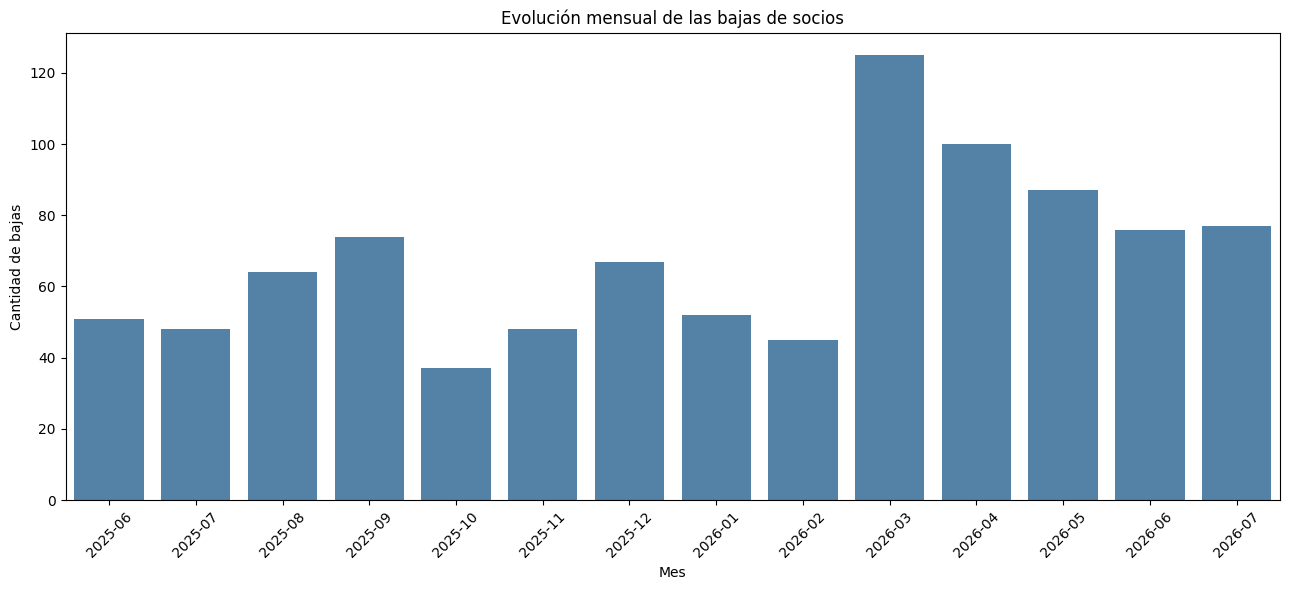

In [55]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=tabla_mensual,
    x="MES",
    y="CANTIDAD DE BAJAS",
    color="steelblue"
)

plt.title("Evolución mensual de las bajas de socios")
plt.xlabel("Mes")
plt.ylabel("Cantidad de bajas")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**3. ¿Cómo varían las bajas según la edad de los socios?**


**Análisis de las bajas según la edad de los socios**

En esta etapa se analiza cómo se distribuyen las bajas según la edad de los socios, con el objetivo de identificar qué grupos etarios presentan una mayor cantidad de desvinculaciones.

Este análisis permitirá observar si existe una mayor concentración de bajas en determinados rangos de edad.

In [56]:
df["EDAD"].describe()

,EDAD
count,951
unique,92
top,17 años
freq,45


In [57]:
df["EDAD"].value_counts().sort_index()

,count
EDAD,
0 años,3
1 año,4
10 años,17
11 años,20
12 años,23
...,...
89 años,1
9 años,22
90 años,1


Para analizar la distribución de las bajas según la edad, primero se revisan los valores registrados y se verifica su ordenamiento. Dado que las edades están expresadas como texto, es necesario convertirlas a valores numéricos para facilitar su análisis y posterior agrupación.

In [58]:
df["EDAD"].str.extract(r"(\d+)")[0].astype(int).value_counts().sort_index()

,count
0,
0,3
1,4
2,7
3,11
4,14
...,...
88,1
89,1
90,1


In [60]:
df["GRUPO_EDAD"] = pd.cut(
    df["EDAD"].str.extract(r"(\d+)")[0].astype(int),
    bins=[-1, 4, 10, 18, 29, 39, 49, 59, 69, 100],
    labels=[
        "0 a 4 años",
        "5 a 10 años",
        "11 a 18 años",
        "19 a 29 años",
        "30 a 39 años",
        "40 a 49 años",
        "50 a 59 años",
        "60 a 69 años",
        "70 años o más"
    ]
)

df["GRUPO_EDAD"].value_counts().sort_index()

,count
GRUPO_EDAD,
0 a 4 años,39
5 a 10 años,122
11 a 18 años,219
19 a 29 años,148
30 a 39 años,90
40 a 49 años,155
50 a 59 años,85
60 a 69 años,40
70 años o más,53


### Distribución de las bajas según la edad de los socios

Para analizar la distribución de las bajas según la edad, se agruparon los registros en nueve rangos etarios.

Los resultados muestran que el grupo de 11 a 18 años presenta la mayor cantidad de bajas, con 219 registros, seguido por el grupo de 40 a 49 años, con 155, y el de 19 a 29 años, con 148.

Por otro lado, el grupo de 60 a 69 años registra la menor cantidad de bajas, con 40 casos.

Esta distribución permite identificar diferencias en la cantidad de bajas entre los distintos grupos etarios durante el período analizado.

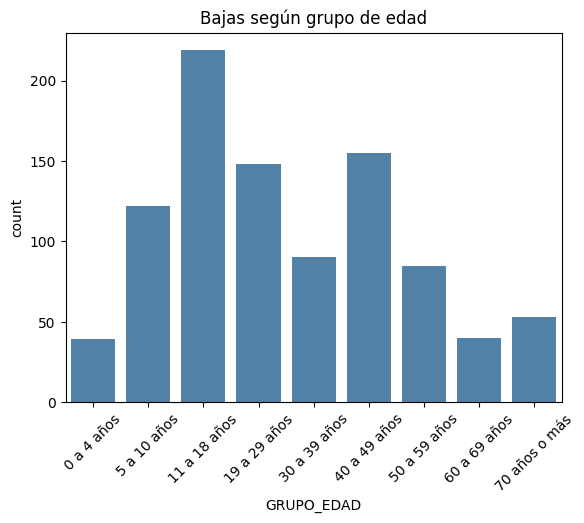

In [63]:
sns.countplot(data=df, x="GRUPO_EDAD", color="steelblue")
plt.title("Bajas según grupo de edad")
plt.xticks(rotation=45)
plt.show()

**4. ¿Cómo varían las bajas según la antigüedad de los socios?**

### Análisis de las bajas según la antigüedad de los socios

En esta etapa se analiza cómo se distribuyen las bajas según la antigüedad de los socios, con el objetivo de identificar si las desvinculaciones se concentran en socios recientes o en aquellos que llevan más tiempo en el club.

In [66]:
antiguedad = df["ANTIGÜEDAD COMO SOCIO"]

print("Total de bajas:", antiguedad.count())
print("Antigüedades diferentes:", antiguedad.nunique())
print("Antigüedad más frecuente:", antiguedad.mode()[0])
print("Cantidad de socios con esa antigüedad:", antiguedad.value_counts().iloc[0])

Total de bajas: 951
Antigüedades diferentes: 39
Antigüedad más frecuente: 0 años
Cantidad de socios con esa antigüedad: 259


### Exploración de la antigüedad de los socios

Se realiza una primera revisión de la antigüedad de los socios para conocer la cantidad de bajas registradas, los distintos años de antigüedad y cuál es el valor que más se repite.

### Distribución de las bajas según los años de antigüedad

Se analiza la cantidad de bajas correspondiente a cada año de antigüedad, para conocer cómo se distribuyen los registros y establecer grupos que permitan comparar los resultados.

In [67]:
tabla_antiguedad = df["ANTIGÜEDAD COMO SOCIO"].value_counts().rename_axis("ANTIGÜEDAD").reset_index(name="CANTIDAD DE BAJAS")

tabla_antiguedad["ORDEN"] = tabla_antiguedad["ANTIGÜEDAD"].str.extract(r"(\d+)").astype(int)

display(tabla_antiguedad.sort_values("ORDEN").drop(columns="ORDEN"))

,ANTIGÜEDAD,CANTIDAD DE BAJAS
0,0 años,259
1,1 año,186
2,2 años,108
3,3 años,106
4,4 años,93
5,5 años,37
6,6 años,24
7,7 años,18
13,8 años,7
17,9 años,5


### Agrupación de las bajas según la antigüedad

Para facilitar el análisis, se agruparon los años de antigüedad en cinco categorías. Esta clasificación permite comparar las bajas entre socios recientes y aquellos que llevan más tiempo en el club.

In [68]:
df["GRUPO_ANTIGUEDAD"] = pd.cut(
    df["ANTIGÜEDAD COMO SOCIO"].str.extract(r"(\d+)")[0].astype(int),
    bins=[-1, 0, 1, 4, 9, 25, 40, 100],
    labels=[
        "0 años",
        "1 año",
        "2 a 4 años",
        "5 a 9 años",
        "10 a 25 años",
        "26 a 40 años",
        "41 años o más"
    ]
)

df["GRUPO_ANTIGUEDAD"].value_counts().sort_index()

,count
GRUPO_ANTIGUEDAD,
0 años,259
1 año,186
2 a 4 años,307
5 a 9 años,91
10 a 25 años,90
26 a 40 años,9
41 años o más,9


### Resultados de las bajas según la antigüedad

Los resultados muestran que el grupo de 2 a 4 años presenta la mayor cantidad de bajas, con 307 registros. Le siguen los socios con 0 años de antigüedad, con 259 bajas, y aquellos con 1 año, con 186.

A partir de los 5 años de antigüedad, la cantidad de bajas es considerablemente menor.

Esto permite observar una mayor concentración de desvinculaciones entre los socios que llevan menos tiempo en el club.

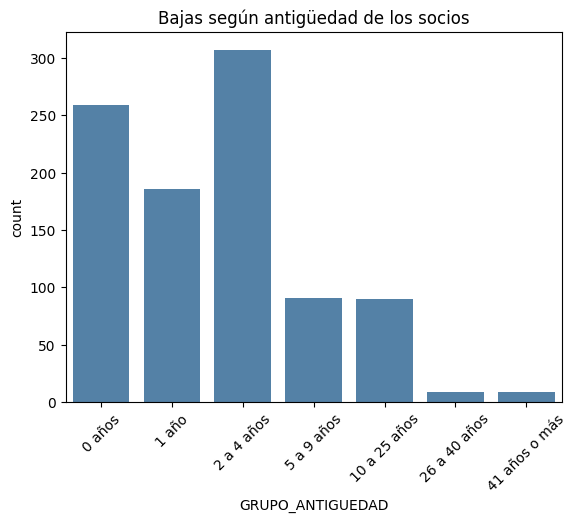

In [69]:
sns.countplot(data=df, x="GRUPO_ANTIGUEDAD", color="steelblue")
plt.title("Bajas según antigüedad de los socios")
plt.xticks(rotation=45)
plt.show()

# Respuesta a la pregunta principal

*¿Por qué se dan de baja los socios y cómo evolucionaron las bajas mes a mes entre junio de 2025 y julio de 2026?*

A partir del análisis de las 951 bajas registradas entre junio de 2025 y julio de 2026, se pudieron identificar los principales motivos de desvinculación y observar cómo evolucionaron las bajas durante el período analizado.

En relación con los motivos, se observó que las razones más frecuentes están vinculadas con la falta de actividad y utilización del club. El motivo más registrado fue “NO HACE NADA EN EL CLUB”, con 144 bajas, seguido por “NO UTILIZA EL CLUB CON FRECUENCIA”, con 126, y “MOTIVOS PERSONALES”, con 102.

En cuanto a la evolución mensual, las bajas presentaron variaciones a lo largo del período. Marzo de 2026 fue el mes con mayor cantidad de bajas, con 125 registros, mientras que octubre de 2025 presentó la menor cantidad, con 37.

Al analizar las bajas según la edad, se identificó que el grupo de 11 a 18 años concentró la mayor cantidad de registros, con 219 bajas. Por otra parte, al observar la antigüedad de los socios, el grupo de 2 a 4 años presentó la mayor cantidad, con 307 bajas, seguido por los socios con 0 años de antigüedad, con 259.

En conjunto, estos resultados permiten reconocer que las bajas se relacionan principalmente con motivos vinculados al uso del club y que su distribución presenta diferencias según el mes, la edad y la antigüedad de los socios.

# Cierre del análisis

El desarrollo de este proyecto permitió trabajar con los datos de bajas de socios, organizarlos y analizarlos para obtener información relevante sobre las desvinculaciones del club. A través de este proceso, fue posible responder las preguntas planteadas al inicio de la investigación y obtener una visión general de los motivos y características de las bajas durante el período estudiado.